# Trabajo Práctico: Análisis Exploratorio y Preprocesamiento
## Dataset: Calidad del Aire y Contaminación (`updated_pollution_dataset.csv`)

Este notebook contiene el **análisis exploratorio de datos (EDA)** y el **preprocesamiento** del dataset de calidad del aire. Cada registro corresponde a una medición en una región, con variables ambientales (temperatura, humedad), concentraciones de contaminantes (PM2.5, PM10, NO2, SO2, CO), variables demográficas/geográficas (proximidad a zonas industriales, densidad poblacional) y la variable objetivo **`Air Quality`** (calidad del aire), con cuatro categorías: *Good*, *Moderate*, *Poor* y *Hazardous*.

## 1. Instrucciones de ejecución

**Librerías necesarias** (Python 3):

- `pandas`: carga y limpieza de datos.
- `numpy`: cálculos y creación de variables nuevas.
- `matplotlib`: gráficos.

Si alguna no está instalada, se puede instalar desde la terminal con:

```
pip3 install pandas numpy matplotlib jupyter
```

**Archivo de datos:** el archivo `updated_pollution_dataset.csv` debe estar **en la misma carpeta que este notebook**, ya que se lee con una ruta relativa.

**Ejecución:** abrir el notebook con Jupyter y ejecutar todas las celdas en orden (*Kernel → Restart & Run All*). Al finalizar se genera el archivo `dataset_limpio.csv` en la misma carpeta.

## 2. Importación de librerías

Se importan las tres librerías que se usan en el trabajo y se configuran algunas opciones de visualización para que las tablas y los gráficos se vean de forma prolija.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Mostrar todas las columnas al imprimir tablas y limitar los decimales
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Tamaño de figura y tamaño de fuente por defecto para los gráficos
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10

## 3. Carga de datos

Se lee el archivo CSV con una ruta relativa, de modo que el notebook funcione en cualquier computadora siempre que el archivo esté en la misma carpeta. Luego se muestran las primeras filas para tener una primera idea del contenido.

In [2]:
# Ruta relativa al archivo de datos
RUTA_DATOS = "updated_pollution_dataset.csv"

df = pd.read_csv(RUTA_DATOS)

# Primeras filas del dataset
df.head()

,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality
0,29.80,59.10,5.20,17.90,18.90,9.20,1.72,6.30,319,Moderate
1,28.30,75.60,2.30,12.20,30.80,9.70,1.64,6.00,611,Moderate
2,23.10,74.70,26.70,33.80,24.40,12.60,1.63,5.20,619,Moderate
3,27.10,39.10,6.10,6.30,13.50,5.30,1.15,11.10,551,Good
4,26.50,70.70,6.90,16.00,21.90,5.60,1.01,12.70,303,Good


Se definen además dos listas auxiliares que se reutilizan a lo largo del notebook: el nombre de la variable objetivo, el orden lógico de sus categorías (de mejor a peor calidad del aire) y la lista de variables numéricas.

In [3]:
# Variable objetivo y orden lógico de sus clases (de mejor a peor calidad del aire)
OBJETIVO = "Air Quality"
ORDEN_CLASES = ["Good", "Moderate", "Poor", "Hazardous"]

# Variables numéricas (todas las columnas excepto la objetivo)
VARIABLES_NUMERICAS = df.drop(columns=OBJETIVO).columns.tolist()
print("Variables numéricas:", VARIABLES_NUMERICAS)

Variables numéricas: ['Temperature', 'Humidity', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'Proximity_to_Industrial_Areas', 'Population_Density']


## 4. Análisis exploratorio de datos

### 4.1 Dimensiones del dataset

Se verifica la cantidad de filas (registros) y columnas (variables) para conocer el tamaño del problema.

In [4]:
filas, columnas = df.shape
print(f"Cantidad de filas: {filas}")
print(f"Cantidad de columnas: {columnas}")

Cantidad de filas: 5000
Cantidad de columnas: 10


El dataset tiene 5000 registros y 10 columnas: 9 variables explicativas y 1 variable objetivo.

### 4.2 Tipos de datos

Se revisa el tipo de cada columna para confirmar que las variables numéricas se hayan leído como números y que la variable objetivo sea categórica (texto).

In [5]:
# Tipo de dato de cada columna junto con la cantidad de valores no nulos
tipos = pd.DataFrame({
    "Tipo de dato": df.dtypes.astype(str),
    "Valores no nulos": df.notna().sum()
})
tipos

,Tipo de dato,Valores no nulos
Temperature,float64,5000
Humidity,float64,5000
PM2.5,float64,5000
PM10,float64,5000
NO2,float64,5000
SO2,float64,5000
CO,float64,5000
Proximity_to_Industrial_Areas,float64,5000
Population_Density,int64,5000
Air Quality,str,5000


Las ocho variables de medición son de tipo decimal (`float64`), `Population_Density` es entera (`int64`) y `Air Quality` es texto. Los tipos son coherentes con el significado de cada variable, por lo que no es necesario hacer conversiones.

### 4.3 Estadísticas descriptivas

Se calculan medidas de posición y dispersión (media, desvío, mínimo, cuartiles y máximo) de cada variable numérica. Esto permite detectar rápidamente rangos sospechosos, asimetrías y posibles valores imposibles.

In [6]:
# Estadísticas descriptivas transpuestas (una fila por variable) para facilitar la lectura
df[VARIABLES_NUMERICAS].describe().T

,count,mean,std,min,25%,50%,75%,max
Temperature,5000.00,30.03,6.72,13.40,25.10,29.00,34.00,58.60
Humidity,5000.00,70.06,15.86,36.00,58.30,69.80,80.30,128.10
PM2.5,5000.00,20.14,24.55,0.00,4.60,12.00,26.10,295.00
PM10,5000.00,30.22,27.35,-0.20,12.30,21.70,38.10,315.80
NO2,5000.00,26.41,8.90,7.40,20.10,25.30,31.90,64.90
SO2,5000.00,10.01,6.75,-6.20,5.10,8.00,13.72,44.90
CO,5000.00,1.50,0.55,0.65,1.03,1.41,1.84,3.72
Proximity_to_Industrial_Areas,5000.00,8.43,3.61,2.50,5.40,7.90,11.10,25.80
Population_Density,5000.00,497.42,152.75,188.00,381.00,494.00,600.00,957.00


Observaciones a partir de la tabla:

- **PM2.5 y PM10** tienen un máximo muy alejado del tercer cuartil (295 y 315.8 frente a 26.1 y 38.1), lo que indica distribuciones con cola larga a la derecha y presencia de valores extremos.
- **SO2 y PM10** tienen valores mínimos **negativos**, lo cual es físicamente imposible para una concentración.
- **Humidity** tiene un máximo de 128.1, pero la humedad relativa está expresada en porcentaje y **no puede superar el 100 %**.
- El resto de las variables presenta rangos razonables.

Estos puntos se analizan en detalle en las secciones siguientes.

### 4.4 Valores nulos

Se cuenta la cantidad de valores faltantes por columna, ya que los nulos deben tratarse antes de cualquier modelado.

In [7]:
nulos = df.isna().sum()
print("Valores nulos por columna:")
print(nulos)
print(f"\nTotal de valores nulos: {nulos.sum()}")

Valores nulos por columna:
Temperature                      0
Humidity                         0
PM2.5                            0
PM10                             0
NO2                              0
SO2                              0
CO                               0
Proximity_to_Industrial_Areas    0
Population_Density               0
Air Quality                      0
dtype: int64

Total de valores nulos: 0


El dataset **no tiene valores nulos**, por lo que no es necesario imputar ni eliminar registros por este motivo.

### 4.5 Registros duplicados

Se buscan filas completamente repetidas, que podrían sesgar el análisis al darle más peso a ciertas observaciones.

In [8]:
cantidad_duplicados = df.duplicated().sum()
print(f"Cantidad de filas duplicadas: {cantidad_duplicados}")

Cantidad de filas duplicadas: 0


No hay filas duplicadas, por lo que todos los registros se conservan.

### 4.6 Valores imposibles

Hay restricciones físicas que los datos deben cumplir:

- Las **concentraciones de contaminantes** (PM2.5, PM10, NO2, SO2, CO), la **distancia** a zonas industriales y la **densidad poblacional** no pueden ser negativas.
- La **humedad relativa** es un porcentaje, por lo que debe estar entre 0 y 100.

Se cuenta cuántos registros violan cada una de estas restricciones.

In [9]:
# Cantidad de valores negativos por variable
negativos = (df[VARIABLES_NUMERICAS] < 0).sum()
print("Cantidad de valores negativos por variable:")
print(negativos[negativos > 0])

Cantidad de valores negativos por variable:
PM10     1
SO2     30
dtype: int64


In [10]:
# Detalle de los valores negativos encontrados
for columna in negativos[negativos > 0].index:
    valores = df.loc[df[columna] < 0, columna]
    print(f"{columna}: {len(valores)} valores negativos, "
          f"mínimo = {valores.min()}, mediana = {valores.median()}, máximo = {valores.max()}")

PM10: 1 valores negativos, mínimo = -0.2, mediana = -0.2, máximo = -0.2
SO2: 30 valores negativos, mínimo = -6.2, mediana = -0.4, máximo = -0.1


Hay **30 valores negativos en SO2** y **1 en PM10**. Son todos valores muy cercanos a cero (la mediana de los negativos de SO2 es -0.4), lo que sugiere errores de medición del sensor cuando la concentración real es muy baja, cercana a su límite de detección.

A continuación se revisa la humedad mayor a 100 %.

In [11]:
# Registros con humedad relativa mayor a 100 %
humedad_imposible = df[df["Humidity"] > 100]
print(f"Registros con humedad mayor a 100 %: {len(humedad_imposible)}")
print("\nDistribución por clase de calidad del aire:")
print(humedad_imposible[OBJETIVO].value_counts())

Registros con humedad mayor a 100 %: 195

Distribución por clase de calidad del aire:
Air Quality
Hazardous    130
Poor          65
Name: count, dtype: int64


Hay **195 registros con humedad mayor a 100 %**, todos pertenecientes a las clases *Poor* y *Hazardous*. Como la humedad relativa no puede superar el 100 %, son errores de medición, pero su presencia en las clases de peor calidad indica que corresponden a condiciones de humedad muy alta.

Por último, se verifica una relación física entre contaminantes: el PM2.5 (partículas de menos de 2.5 µm) es una fracción del PM10 (partículas de menos de 10 µm), por lo que en teoría PM2.5 no debería superar a PM10.

In [12]:
pm25_mayor_pm10 = (df["PM2.5"] > df["PM10"]).sum()
print(f"Registros con PM2.5 mayor que PM10: {pm25_mayor_pm10} "
      f"({pm25_mayor_pm10 / len(df) * 100:.2f} % del total)")

Registros con PM2.5 mayor que PM10: 32 (0.64 % del total)


Hay 32 registros (0.64 %) donde PM2.5 supera a PM10. Es una inconsistencia menor que puede deberse a que ambos contaminantes se miden con sensores distintos. Como no es posible saber cuál de los dos valores es el erróneo, estos registros se conservan sin modificar; la variable de cociente PM2.5/PM10 que se crea en el preprocesamiento permitirá identificarlos.

### 4.7 Detección de outliers con el método IQR

Se aplica el método del **rango intercuartílico (IQR)**: un valor se considera atípico si está por debajo de `Q1 - 1.5·IQR` o por encima de `Q3 + 1.5·IQR`, donde `IQR = Q3 - Q1`. Es un método robusto porque se basa en cuartiles, que no se ven afectados por los propios valores extremos.

In [13]:
# Cálculo de cuartiles, IQR y límites para cada variable numérica
q1 = df[VARIABLES_NUMERICAS].quantile(0.25)
q3 = df[VARIABLES_NUMERICAS].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Máscara booleana: True si el valor es outlier en su variable
es_outlier = (df[VARIABLES_NUMERICAS] < limite_inferior) | (df[VARIABLES_NUMERICAS] > limite_superior)

resumen_outliers = pd.DataFrame({
    "Límite inferior": limite_inferior,
    "Límite superior": limite_superior,
    "Cantidad de outliers": es_outlier.sum(),
    "Porcentaje (%)": es_outlier.mean() * 100
})
resumen_outliers

,Límite inferior,Límite superior,Cantidad de outliers,Porcentaje (%)
Temperature,11.75,47.35,72,1.44
Humidity,25.30,113.30,19,0.38
PM2.5,-27.65,58.35,352,7.04
PM10,-26.40,76.80,324,6.48
NO2,2.40,49.60,73,1.46
SO2,-7.84,26.66,124,2.48
CO,-0.19,3.06,45,0.90
Proximity_to_Industrial_Areas,-3.15,19.65,16,0.32
Population_Density,52.50,928.50,7,0.14


Todas las variables tienen algún outlier, pero las más afectadas son **PM2.5 (7 %)** y **PM10 (6.5 %)**, seguidas por SO2. Antes de decidir qué hacer con ellos, es importante ver **a qué clase pertenecen** los registros atípicos.

In [14]:
# Registros que son outlier en al menos una variable, según su clase
fila_con_outlier = es_outlier.any(axis=1)

outliers_por_clase = pd.DataFrame({
    "Registros con outlier": df.loc[fila_con_outlier, OBJETIVO].value_counts(),
    "Total de la clase": df[OBJETIVO].value_counts()
}).reindex(ORDEN_CLASES)
outliers_por_clase["Porcentaje de la clase (%)"] = (
    outliers_por_clase["Registros con outlier"] / outliers_por_clase["Total de la clase"] * 100
)

print(f"Registros con al menos un outlier: {fila_con_outlier.sum()} "
      f"({fila_con_outlier.mean() * 100:.2f} % del total)\n")
outliers_por_clase

Registros con al menos un outlier: 593 (11.86 % del total)



,Registros con outlier,Total de la clase,Porcentaje de la clase (%)
Air Quality,,,
Good,19,2000,0.95
Moderate,82,1500,5.47
Poor,179,1000,17.90
Hazardous,313,500,62.60


El resultado es muy claro: los outliers **no están distribuidos al azar**. El **62.6 % de los registros *Hazardous*** y el 17.9 % de los *Poor* tienen al menos un valor atípico, mientras que en la clase *Good* esto ocurre en menos del 1 % de los casos. Es decir, los valores extremos son justamente los que caracterizan a las situaciones de contaminación peligrosa. Esto será clave para la decisión de tratamiento en el preprocesamiento.

### 4.8 Distribución de la variable objetivo

Se analiza cuántos registros hay de cada clase para saber si el dataset está balanceado, lo cual es importante para elegir métricas y estrategias de modelado más adelante.

             Cantidad  Porcentaje (%)
Air Quality                          
Good             2000           40.00
Moderate         1500           30.00
Poor             1000           20.00
Hazardous         500           10.00


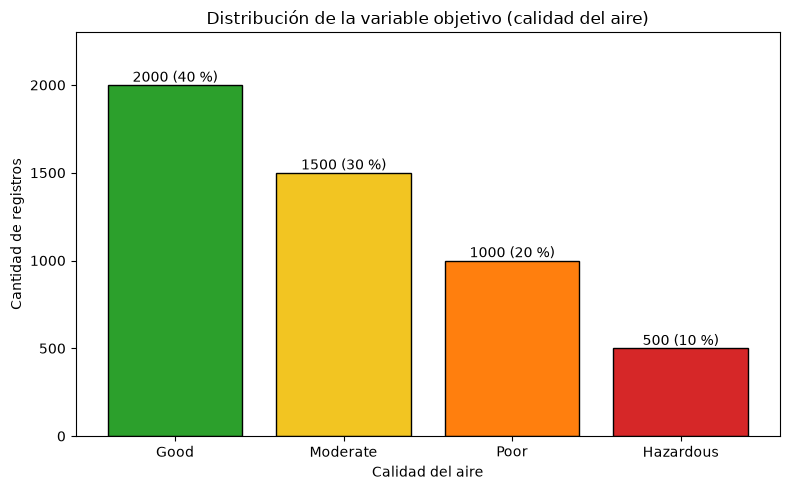

In [15]:
frecuencia_clases = df[OBJETIVO].value_counts().reindex(ORDEN_CLASES)
porcentaje_clases = frecuencia_clases / len(df) * 100

print(pd.DataFrame({"Cantidad": frecuencia_clases, "Porcentaje (%)": porcentaje_clases}))

# Gráfico de barras con la cantidad de registros por clase
colores_clases = ["#2ca02c", "#f2c522", "#ff7f0e", "#d62728"]

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(ORDEN_CLASES, frecuencia_clases, color=colores_clases, edgecolor="black")
ax.bar_label(barras, labels=[f"{c} ({p:.0f} %)" for c, p in zip(frecuencia_clases, porcentaje_clases)])
ax.set_title("Distribución de la variable objetivo (calidad del aire)")
ax.set_xlabel("Calidad del aire")
ax.set_ylabel("Cantidad de registros")
ax.set_ylim(0, frecuencia_clases.max() * 1.15)
plt.tight_layout()
plt.show()

**Interpretación:** la variable objetivo está **desbalanceada**. La clase *Good* representa el 40 % de los datos, *Moderate* el 30 %, *Poor* el 20 % y *Hazardous* solo el 10 %. La clase más crítica (*Hazardous*) es la minoritaria, por lo que en una etapa posterior de modelado convendrá usar métricas que no dependan solo de la exactitud (por ejemplo, F1 por clase) y una partición estratificada. Además, este desbalance refuerza la necesidad de **no eliminar registros** de las clases minoritarias durante la limpieza.

### 4.9 Histogramas de las variables numéricas

Se grafican los histogramas para observar la forma de la distribución de cada variable: simetría, asimetría, concentración de valores y colas.

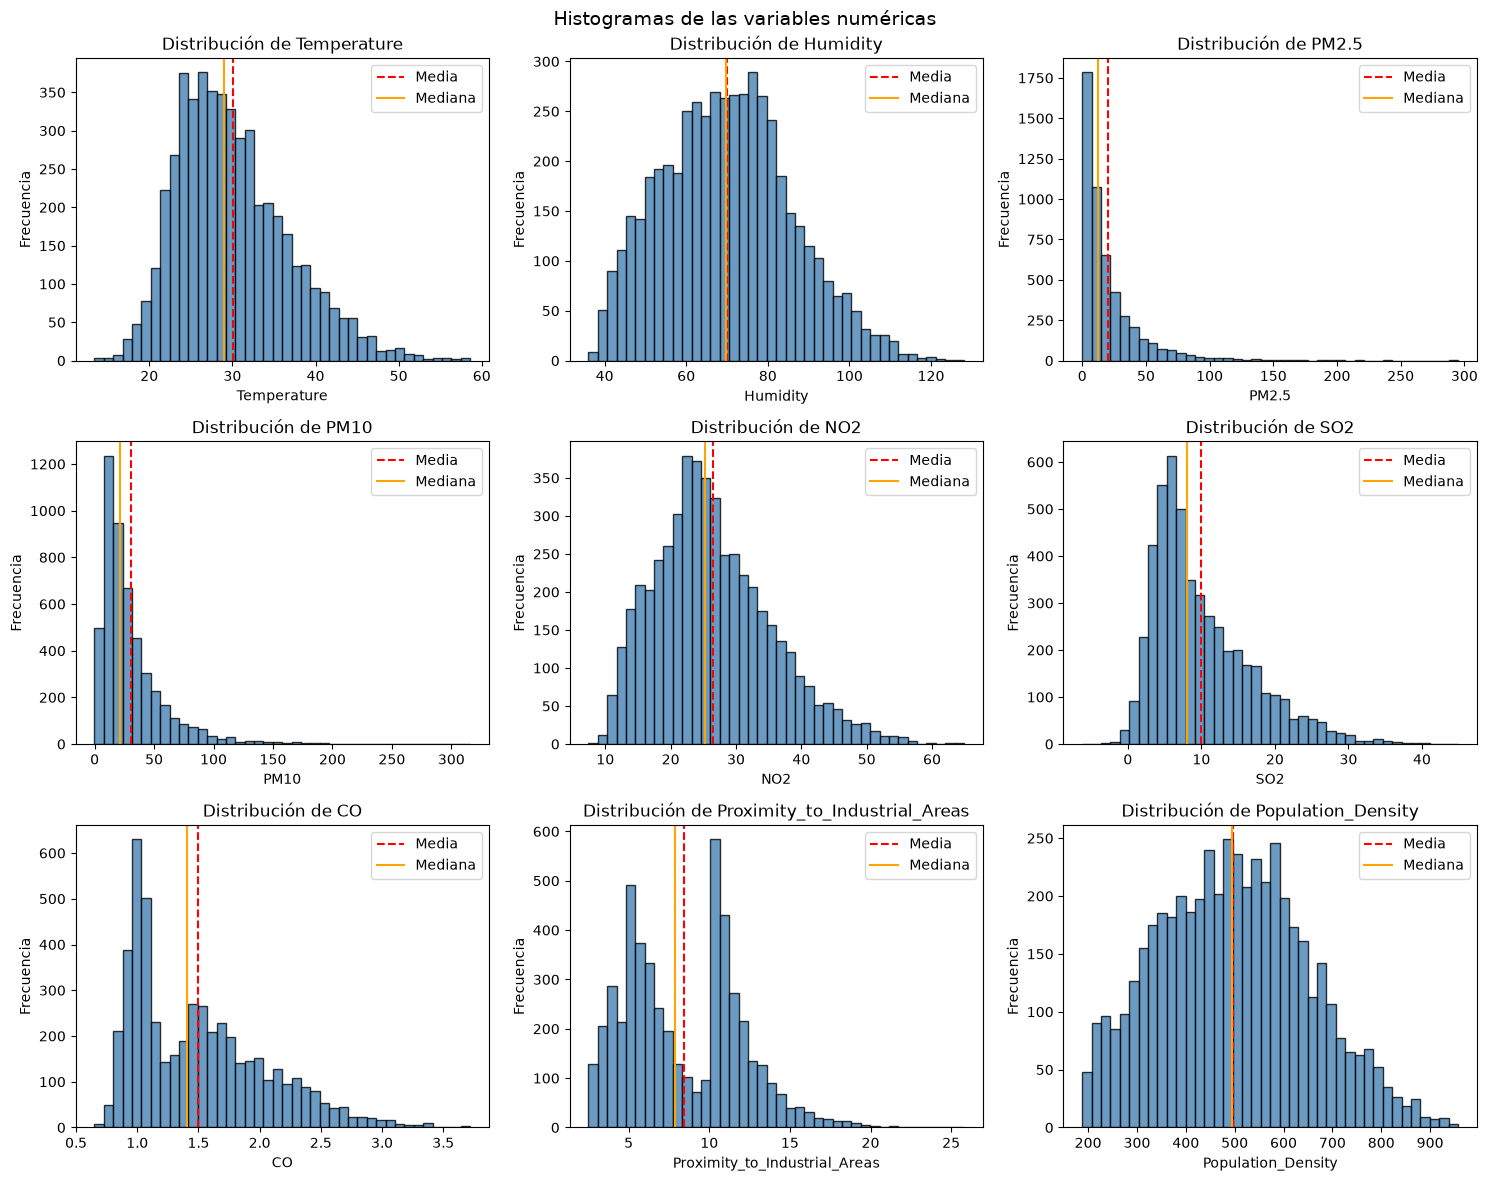

In [16]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 12))

for ax, columna in zip(ejes.flatten(), VARIABLES_NUMERICAS):
    ax.hist(df[columna], bins=40, color="steelblue", edgecolor="black", alpha=0.8)
    ax.axvline(df[columna].mean(), color="red", linestyle="--", label="Media")
    ax.axvline(df[columna].median(), color="orange", linestyle="-", label="Mediana")
    ax.set_title(f"Distribución de {columna}")
    ax.set_xlabel(columna)
    ax.set_ylabel("Frecuencia")
    ax.legend()

fig.suptitle("Histogramas de las variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación:**

- **PM2.5 y PM10** tienen una fuerte **asimetría positiva**: la mayoría de los valores son bajos, pero hay una cola larga hacia valores altos. La media queda claramente a la derecha de la mediana. Este tipo de distribución es típico de concentraciones de contaminantes y suele mejorar con una transformación logarítmica.
- **SO2, NO2, CO** y **Proximity_to_Industrial_Areas** también son asimétricas a la derecha, aunque en menor medida.
- **Temperature, Humidity y Population_Density** tienen distribuciones más cercanas a la simétrica, con media y mediana similares.
- En Humidity se observa una pequeña cola que supera el valor 100, que corresponde a los valores imposibles detectados antes.

### 4.10 Boxplots por clase de calidad del aire

Se grafica un boxplot de cada variable separado por clase. Esto permite ver qué variables **diferencian** a las clases (y por lo tanto serán útiles para predecir) y en qué clases se concentran los valores atípicos.

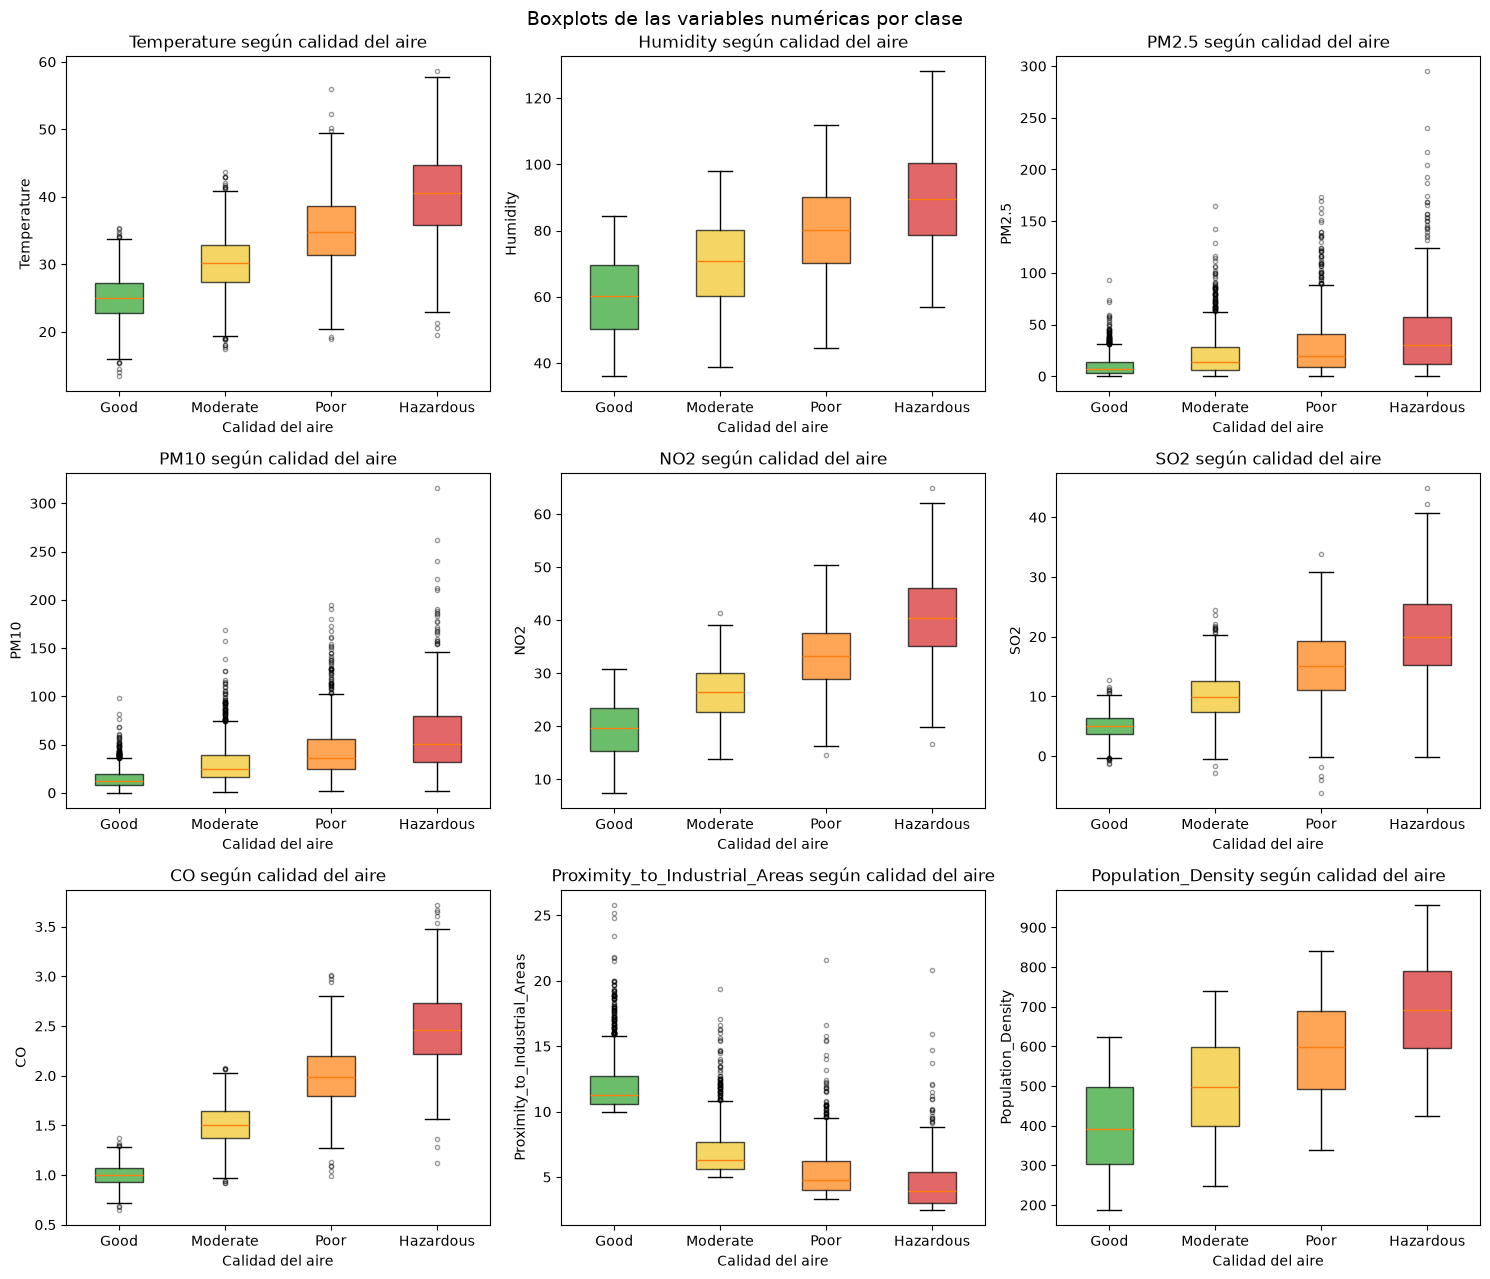

In [17]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 13))

for ax, columna in zip(ejes.flatten(), VARIABLES_NUMERICAS):
    # Una lista de valores por clase, respetando el orden lógico
    datos_por_clase = [df.loc[df[OBJETIVO] == clase, columna] for clase in ORDEN_CLASES]
    cajas = ax.boxplot(datos_por_clase, patch_artist=True,
                       flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
    ax.set_xticks(range(1, len(ORDEN_CLASES) + 1), ORDEN_CLASES)
    for caja, color in zip(cajas["boxes"], colores_clases):
        caja.set_facecolor(color)
        caja.set_alpha(0.7)
    ax.set_title(f"{columna} según calidad del aire")
    ax.set_xlabel("Calidad del aire")
    ax.set_ylabel(columna)

fig.suptitle("Boxplots de las variables numéricas por clase", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación:**

- En casi todas las variables se ve un **patrón ordenado**: a medida que empeora la calidad del aire (*Good → Moderate → Poor → Hazardous*), aumentan la temperatura, la humedad, los contaminantes y la densidad poblacional.
- **Proximity_to_Industrial_Areas** muestra el patrón inverso: cuanto **más cerca** de una zona industrial (menor distancia), peor es la calidad del aire.
- **CO, NO2 y la proximidad industrial** son las variables que mejor separan las clases, con cajas poco superpuestas.
- Los valores extremos de **PM2.5 y PM10** aparecen sobre todo en las clases *Poor* y *Hazardous*, lo que confirma que los outliers son información real sobre episodios de alta contaminación y no simples errores.

### 4.11 Matriz de correlación

Se calcula la correlación de Pearson entre las variables numéricas para medir la intensidad de sus relaciones lineales. Esto permite detectar variables redundantes (muy correlacionadas entre sí) y anticipar cuáles se relacionan más con la calidad del aire. Para incluir la variable objetivo, se usa temporalmente un código ordinal (0 = *Good* … 3 = *Hazardous*), sin modificar todavía el dataset.

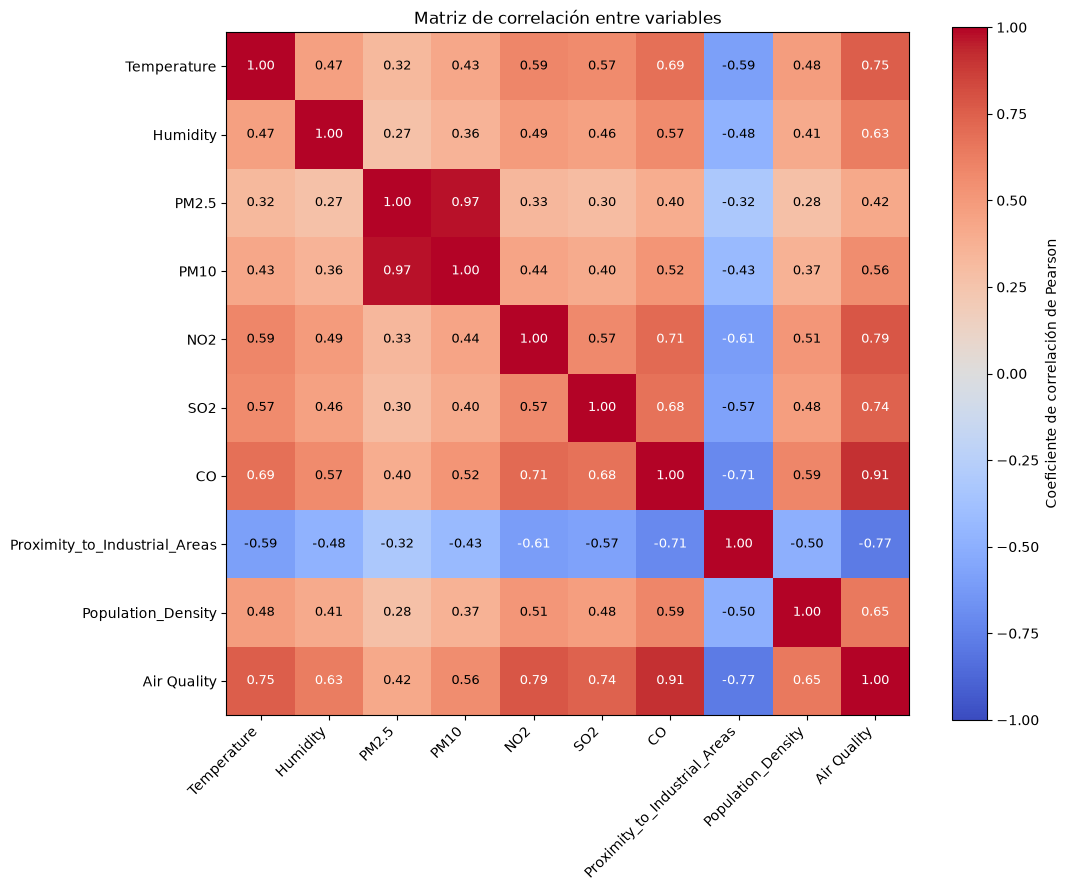

In [18]:
# Copia temporal con la variable objetivo codificada solo para calcular correlaciones
df_correlacion = df.copy()
df_correlacion[OBJETIVO] = df_correlacion[OBJETIVO].map(
    {clase: codigo for codigo, clase in enumerate(ORDEN_CLASES)}
)
matriz_correlacion = df_correlacion.corr()

fig, ax = plt.subplots(figsize=(11, 9))
imagen = ax.imshow(matriz_correlacion, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(imagen, ax=ax, label="Coeficiente de correlación de Pearson")

# Etiquetas de los ejes
etiquetas = matriz_correlacion.columns
ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=45, ha="right")
ax.set_yticks(range(len(etiquetas)), etiquetas)

# Valor de la correlación dentro de cada celda
for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        valor = matriz_correlacion.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center",
                color="white" if abs(valor) > 0.6 else "black", fontsize=9)

ax.set_title("Matriz de correlación entre variables")
plt.tight_layout()
plt.show()

In [19]:
# Correlación de cada variable con la calidad del aire, ordenada de mayor a menor en valor absoluto
correlacion_objetivo = matriz_correlacion[OBJETIVO].drop(OBJETIVO)
correlacion_objetivo.reindex(correlacion_objetivo.abs().sort_values(ascending=False).index)

CO                               0.91
NO2                              0.79
Proximity_to_Industrial_Areas   -0.77
Temperature                      0.75
SO2                              0.74
Population_Density               0.65
Humidity                         0.63
PM10                             0.56
PM2.5                            0.42
Name: Air Quality, dtype: float64

**Interpretación:**

- **CO** (0.91) es la variable más correlacionada con la calidad del aire, seguida por **NO2** (0.79) y **Proximity_to_Industrial_Areas** (-0.77). La proximidad tiene signo negativo: menor distancia a la industria, peor calidad.
- **Temperature, SO2, Population_Density y Humidity** también tienen correlaciones moderadas a altas con la objetivo (entre 0.63 y 0.75).
- **PM2.5** (0.42) tiene la correlación más baja con la objetivo. Esto no significa que no sea relevante: la correlación de Pearson mide relaciones *lineales* y se ve muy afectada por la asimetría y los valores extremos de esta variable. Por eso en el preprocesamiento se crea su versión logarítmica.
- **PM2.5 y PM10** están muy correlacionadas entre sí (0.97), lo cual es esperable porque el PM2.5 es una fracción del PM10. Esta redundancia debe tenerse en cuenta en el modelado.
- Entre las variables explicativas, la siguiente correlación más alta es la de CO con NO2 y con la proximidad industrial (0.71 en valor absoluto). Fuera del par PM2.5–PM10, no hay correlaciones tan altas como para indicar redundancia total.

### 4.12 Conclusiones del análisis exploratorio

1. El dataset no tiene nulos ni duplicados.
2. Hay **valores físicamente imposibles**: 30 negativos en SO2, 1 en PM10 y 195 humedades mayores a 100 %.
3. Hay outliers en todas las variables, especialmente en PM2.5 y PM10, pero **se concentran en las clases *Poor* y *Hazardous***: representan episodios reales de contaminación.
4. La variable objetivo está **desbalanceada** (40 / 30 / 20 / 10 %).
5. PM2.5 y PM10 son muy asimétricas, lo que justifica transformarlas.
6. CO, NO2 y la proximidad industrial son las variables más relacionadas con la calidad del aire.

## 5. Preprocesamiento

Se trabaja sobre una **copia** del dataset original, para conservar los datos crudos intactos y poder comparar antes y después de cada transformación.

In [20]:
df_limpio = df.copy()

### 5.1 Tratamiento de valores imposibles

**Valores negativos (SO2 y PM10).** Una concentración no puede ser negativa. Las opciones eran eliminar los registros, imputarlos con la mediana o reemplazarlos por cero. Se decide **reemplazarlos por 0** porque:

- Son muy pocos (31 en total, 0.6 % de los registros), por lo que eliminarlos no tiene sentido: se perderían también los valores válidos de las demás variables.
- Todos están muy cerca de cero (la mayoría entre -1 y 0), lo que indica que la concentración real era muy baja y el sensor registró un pequeño error por debajo de su límite de detección. El valor más cercano físicamente posible es 0.
- Imputar con la mediana (≈10 para SO2) sería menos fiel al dato, porque asignaría una concentración mucho más alta que la medida.

**Humedad mayor a 100 % (Humidity).** La humedad relativa no puede superar el 100 %. Se decide **acotar estos valores a 100** porque:

- Son 195 registros (3.9 %), todos de las clases *Poor* y *Hazardous*: eliminarlos reduciría todavía más las clases minoritarias.
- El dato indica claramente una humedad muy alta (saturación), por lo que 100 es el valor válido más cercano y conserva esa información.

In [21]:
# Variables que no pueden tomar valores negativos (concentraciones, distancia y densidad)
VARIABLES_NO_NEGATIVAS = ["PM2.5", "PM10", "NO2", "SO2", "CO",
                          "Proximity_to_Industrial_Areas", "Population_Density"]

# Reemplazo de negativos por 0 (clip con límite inferior 0)
df_limpio[VARIABLES_NO_NEGATIVAS] = df_limpio[VARIABLES_NO_NEGATIVAS].clip(lower=0)

# Humedad relativa acotada a un máximo de 100 %
df_limpio["Humidity"] = df_limpio["Humidity"].clip(upper=100)

# Verificación
print("Valores negativos restantes:", (df_limpio[VARIABLES_NO_NEGATIVAS] < 0).sum().sum())
print("Registros con humedad > 100 %:", (df_limpio["Humidity"] > 100).sum())
print(f"Rango de SO2: {df_limpio['SO2'].min()} a {df_limpio['SO2'].max()}")
print(f"Rango de Humidity: {df_limpio['Humidity'].min()} a {df_limpio['Humidity'].max()}")

Valores negativos restantes: 0
Registros con humedad > 100 %: 0
Rango de SO2: 0.0 a 44.9
Rango de Humidity: 36.0 a 100.0


Se verifica que ya no quedan valores negativos ni humedades por encima de 100 %, y que la cantidad de registros no cambió.

### 5.2 Tratamiento de outliers

Para los outliers detectados con el método IQR se evaluaron tres alternativas:

| Alternativa | Efecto | Problema en este dataset |
|---|---|---|
| Eliminar los registros | Se quitan 593 filas (11.9 %) | Se perdería el 62.6 % de la clase *Hazardous*, que ya es la minoritaria |
| Acotar (winsorizar) a los límites IQR | Los valores extremos se reemplazan por el límite | Se borraría justamente la información que distingue a *Hazardous* y *Poor* |
| **Conservarlos y reducir la asimetría con una transformación** | Se mantienen todos los registros | Ninguno relevante |

Se decide **conservar los outliers**, porque el análisis exploratorio mostró que no son errores de medición sino **valores reales y coherentes** con las clases de peor calidad del aire (están dentro de rangos físicamente posibles y se concentran en *Poor* y *Hazardous*). Eliminarlos o acotarlos haría que el modelo aprenda peor a reconocer las situaciones de contaminación peligrosa, que son las más importantes de detectar.

Para reducir el impacto de la asimetría de **PM2.5 y PM10** (las variables con más outliers), en la sección siguiente se crean sus versiones con transformación logarítmica. Se compara a continuación cómo cambia la proporción de outliers con esa transformación.

In [22]:
def porcentaje_outliers_iqr(serie):
    """Devuelve el porcentaje de valores fuera de los límites IQR de una serie."""
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    fuera = (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)
    return fuera.mean() * 100


for columna in ["PM2.5", "PM10"]:
    original = porcentaje_outliers_iqr(df_limpio[columna])
    transformada = porcentaje_outliers_iqr(np.log1p(df_limpio[columna]))
    print(f"{columna}: {original:.2f} % de outliers en escala original -> "
          f"{transformada:.2f} % en escala logarítmica")

PM2.5: 7.04 % de outliers en escala original -> 0.02 % en escala logarítmica
PM10: 6.48 % de outliers en escala original -> 0.28 % en escala logarítmica


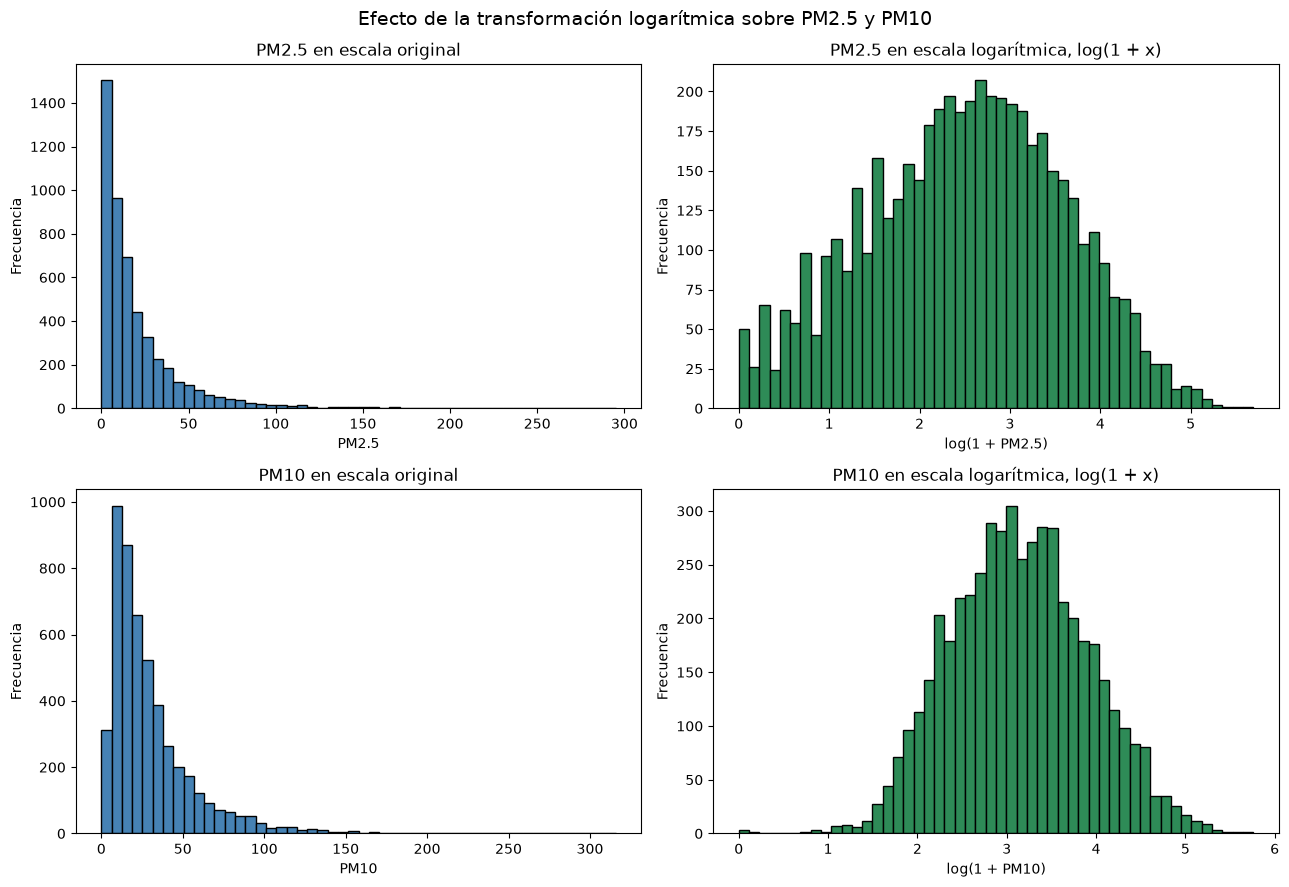

In [23]:
# Comparación visual de PM2.5 y PM10 antes y después de la transformación logarítmica
fig, ejes = plt.subplots(2, 2, figsize=(13, 9))

for fila, columna in enumerate(["PM2.5", "PM10"]):
    ejes[fila, 0].hist(df_limpio[columna], bins=50, color="steelblue", edgecolor="black")
    ejes[fila, 0].set_title(f"{columna} en escala original")
    ejes[fila, 0].set_xlabel(columna)
    ejes[fila, 0].set_ylabel("Frecuencia")

    ejes[fila, 1].hist(np.log1p(df_limpio[columna]), bins=50, color="seagreen", edgecolor="black")
    ejes[fila, 1].set_title(f"{columna} en escala logarítmica, log(1 + x)")
    ejes[fila, 1].set_xlabel(f"log(1 + {columna})")
    ejes[fila, 1].set_ylabel("Frecuencia")

fig.suptitle("Efecto de la transformación logarítmica sobre PM2.5 y PM10", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación:** en escala original, PM2.5 y PM10 tienen una cola derecha muy larga. Con la transformación `log(1 + x)` la distribución se vuelve mucho más simétrica y el porcentaje de outliers baja notablemente, **sin eliminar ni modificar ningún registro**. Se usa `log(1 + x)` en lugar de `log(x)` porque hay valores iguales a 0 (por ejemplo, el PM10 negativo que se llevó a 0), para los que el logaritmo no está definido.

### 5.3 Creación de variables nuevas

Se crean cuatro variables nuevas con `numpy`, cada una con una justificación:

1. **`log_PM2.5`** y **`log_PM10`**: transformación logarítmica `log(1 + x)` para reducir la asimetría y el efecto de los valores extremos, como se mostró antes.
2. **`Ratio_PM2.5_PM10`**: cociente entre PM2.5 y PM10. Indica qué proporción del material particulado corresponde a partículas finas, que son las más dañinas para la salud porque llegan más profundo en las vías respiratorias. Si PM10 vale 0, el cociente no está definido y se asigna 0 (no hay material particulado).
3. **`Indice_Gases`**: índice combinado de los gases contaminantes (NO2, SO2 y CO). Como cada gas tiene una escala distinta, primero se **estandarizan** (se les resta la media y se divide por el desvío) y luego se promedian. Resume en una sola variable el nivel general de contaminación gaseosa.

In [24]:
# 1. Transformación logarítmica de las partículas
df_limpio["log_PM2.5"] = np.log1p(df_limpio["PM2.5"])
df_limpio["log_PM10"] = np.log1p(df_limpio["PM10"])

# 2. Proporción de partículas finas; si PM10 es 0 se asigna 0 para evitar la división por cero
pm25 = df_limpio["PM2.5"].to_numpy()
pm10 = df_limpio["PM10"].to_numpy()
df_limpio["Ratio_PM2.5_PM10"] = np.divide(pm25, pm10, out=np.zeros_like(pm25), where=pm10 > 0)

# 3. Índice de gases: promedio de NO2, SO2 y CO estandarizados (z-score)
gases = df_limpio[["NO2", "SO2", "CO"]].to_numpy()
gases_estandarizados = (gases - np.mean(gases, axis=0)) / np.std(gases, axis=0)
df_limpio["Indice_Gases"] = np.mean(gases_estandarizados, axis=1)

VARIABLES_NUEVAS = ["log_PM2.5", "log_PM10", "Ratio_PM2.5_PM10", "Indice_Gases"]
df_limpio[VARIABLES_NUEVAS].describe().T

,count,mean,std,min,25%,50%,75%,max
log_PM2.5,5000.00,2.50,1.09,0.00,1.72,2.56,3.30,5.69
log_PM10,5000.00,3.14,0.77,0.00,2.59,3.12,3.67,5.76
Ratio_PM2.5_PM10,5000.00,0.56,0.36,0.00,0.36,0.59,0.76,18.00
Indice_Gases,5000.00,-0.00,0.88,-1.41,-0.74,-0.14,0.57,3.00


Se observa que las variables logarítmicas tienen un rango mucho más acotado que las originales, que el cociente PM2.5/PM10 está en su mayoría entre 0 y 1 (los valores mayores a 1 corresponden a los 32 registros inconsistentes detectados en el EDA; el máximo de 18 aparece en un registro con PM10 muy bajo, donde una diferencia mínima se amplifica en el cociente) y que el índice de gases está centrado en 0, como corresponde a un promedio de variables estandarizadas.

Para verificar la utilidad de las nuevas variables, se grafica su distribución por clase.

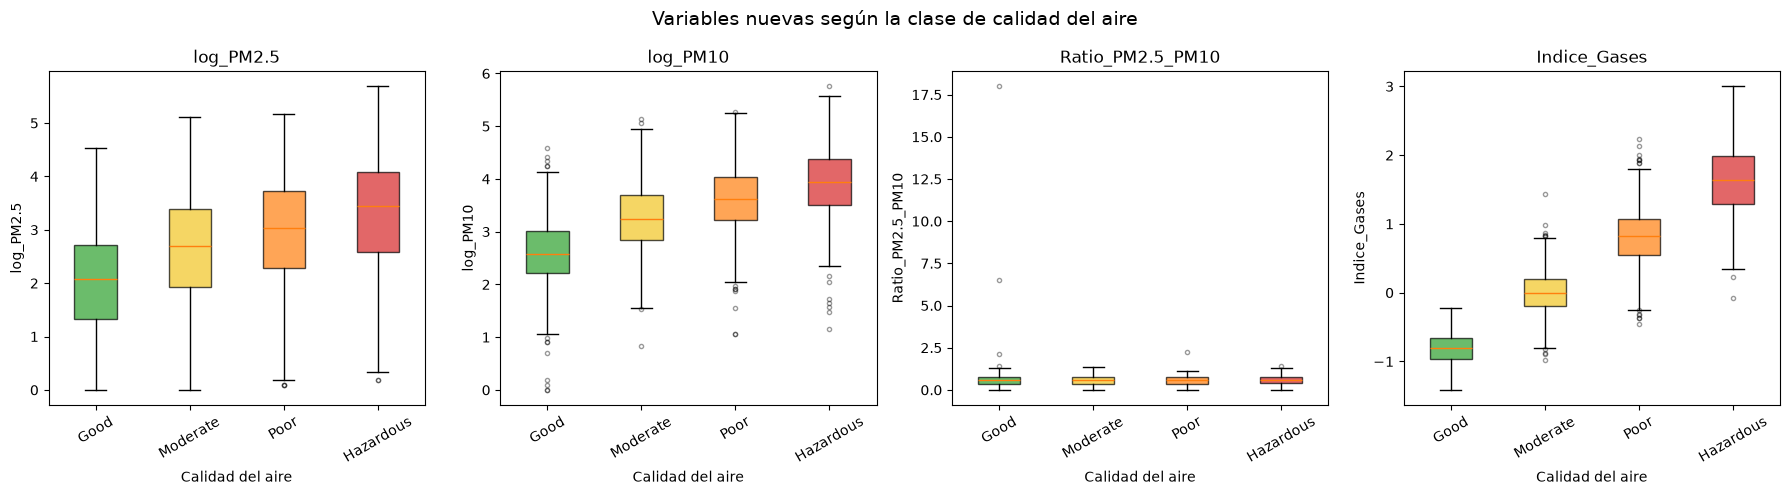

In [25]:
fig, ejes = plt.subplots(1, 4, figsize=(18, 5))

for ax, columna in zip(ejes, VARIABLES_NUEVAS):
    datos_por_clase = [df_limpio.loc[df_limpio[OBJETIVO] == clase, columna] for clase in ORDEN_CLASES]
    cajas = ax.boxplot(datos_por_clase, patch_artist=True,
                       flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
    ax.set_xticks(range(1, len(ORDEN_CLASES) + 1), ORDEN_CLASES, rotation=30)
    for caja, color in zip(cajas["boxes"], colores_clases):
        caja.set_facecolor(color)
        caja.set_alpha(0.7)
    ax.set_title(columna)
    ax.set_xlabel("Calidad del aire")
    ax.set_ylabel(columna)

fig.suptitle("Variables nuevas según la clase de calidad del aire", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación:**

- **`log_PM2.5` y `log_PM10`** muestran con mucha más claridad que las variables originales el aumento progresivo entre clases, porque los valores extremos ya no comprimen la escala del gráfico.
- **`Indice_Gases`** separa muy bien las cuatro clases, con muy poca superposición entre *Good* y *Hazardous*: resume eficazmente la información de los tres gases.
- **`Ratio_PM2.5_PM10`** tiene una distribución parecida en todas las clases, por lo que por sí sola aporta poca capacidad de discriminación; aun así se conserva porque tiene sentido físico y puede aportar en combinación con otras variables.

### 5.4 Codificación de la variable objetivo

Los modelos de aprendizaje automático necesitan que la variable objetivo sea numérica. Como las clases de calidad del aire tienen un **orden natural** (de mejor a peor), se usa una **codificación ordinal** que respeta ese orden:

| Clase | Código |
|---|---|
| Good | 0 |
| Moderate | 1 |
| Poor | 2 |
| Hazardous | 3 |

Se elige esta codificación en lugar de una codificación arbitraria (por ejemplo, alfabética) para que los números reflejen el orden real de gravedad. La columna original de texto se reemplaza por la columna codificada.

In [26]:
# Diccionario de codificación ordinal: Good=0, Moderate=1, Poor=2, Hazardous=3
CODIFICACION_OBJETIVO = {clase: codigo for codigo, clase in enumerate(ORDEN_CLASES)}
print("Codificación utilizada:", CODIFICACION_OBJETIVO)

df_limpio[OBJETIVO] = df_limpio[OBJETIVO].map(CODIFICACION_OBJETIVO)

# Verificación: la cantidad por código debe coincidir con la cantidad por clase original
verificacion_codigos = pd.DataFrame({
    "Clase original": ORDEN_CLASES,
    "Código": [CODIFICACION_OBJETIVO[c] for c in ORDEN_CLASES],
    "Cantidad original": df[OBJETIVO].value_counts().reindex(ORDEN_CLASES).values,
    "Cantidad codificada": df_limpio[OBJETIVO].value_counts().sort_index().values
})
verificacion_codigos

Codificación utilizada: {'Good': 0, 'Moderate': 1, 'Poor': 2, 'Hazardous': 3}


,Clase original,Código,Cantidad original,Cantidad codificada
0,Good,0,2000,2000
1,Moderate,1,1500,1500
2,Poor,2,1000,1000
3,Hazardous,3,500,500


La cantidad de registros por clase es la misma antes y después de codificar, lo que confirma que no se perdió ni se mezcló ninguna categoría.

### 5.5 Verificación final del dataset limpio

Por último, se comprueba que el dataset limpio cumple con todas las condiciones esperadas: sin nulos, sin duplicados, sin valores imposibles, con todas las columnas numéricas y con la misma cantidad de registros que el original.

In [27]:
print(f"Dimensiones del dataset original: {df.shape}")
print(f"Dimensiones del dataset limpio:   {df_limpio.shape}")
print(f"Registros conservados: {len(df_limpio) / len(df) * 100:.0f} %\n")

print("Tipos de datos del dataset limpio:")
print(df_limpio.dtypes)

Dimensiones del dataset original: (5000, 10)
Dimensiones del dataset limpio:   (5000, 14)
Registros conservados: 100 %

Tipos de datos del dataset limpio:
Temperature                      float64
Humidity                         float64
PM2.5                            float64
PM10                             float64
NO2                              float64
SO2                              float64
CO                               float64
Proximity_to_Industrial_Areas    float64
Population_Density                 int64
Air Quality                        int64
log_PM2.5                        float64
log_PM10                         float64
Ratio_PM2.5_PM10                 float64
Indice_Gases                     float64
dtype: object


In [28]:
# Controles automáticos: si alguno falla, la celda se detiene con un error
controles = {
    "Sin valores nulos": df_limpio.isna().sum().sum() == 0,
    "Sin filas duplicadas": df_limpio.duplicated().sum() == 0,
    "Sin valores negativos en variables no negativas": (df_limpio[VARIABLES_NO_NEGATIVAS] < 0).sum().sum() == 0,
    "Humedad entre 0 y 100": df_limpio["Humidity"].between(0, 100).all(),
    "Todas las columnas son numéricas": df_limpio.select_dtypes(include="number").shape[1] == df_limpio.shape[1],
    "Variable objetivo con códigos 0 a 3": set(df_limpio[OBJETIVO].unique()) == {0, 1, 2, 3},
    "Misma cantidad de registros que el original": len(df_limpio) == len(df),
}

for descripcion, resultado in controles.items():
    print(f"[{'OK' if resultado else 'ERROR'}] {descripcion}")

assert all(controles.values()), "El dataset limpio no cumple alguno de los controles."

[OK] Sin valores nulos
[OK] Sin filas duplicadas
[OK] Sin valores negativos en variables no negativas
[OK] Humedad entre 0 y 100
[OK] Todas las columnas son numéricas
[OK] Variable objetivo con códigos 0 a 3
[OK] Misma cantidad de registros que el original


In [29]:
# Estadísticas descriptivas del dataset limpio
df_limpio.describe().T

,count,mean,std,min,25%,50%,75%,max
Temperature,5000.00,30.03,6.72,13.40,25.10,29.00,34.00,58.60
Humidity,5000.00,69.81,15.30,36.00,58.30,69.80,80.30,100.00
PM2.5,5000.00,20.14,24.55,0.00,4.60,12.00,26.10,295.00
PM10,5000.00,30.22,27.35,0.00,12.30,21.70,38.10,315.80
NO2,5000.00,26.41,8.90,7.40,20.10,25.30,31.90,64.90
SO2,5000.00,10.02,6.74,0.00,5.10,8.00,13.72,44.90
CO,5000.00,1.50,0.55,0.65,1.03,1.41,1.84,3.72
Proximity_to_Industrial_Areas,5000.00,8.43,3.61,2.50,5.40,7.90,11.10,25.80
Population_Density,5000.00,497.42,152.75,188.00,381.00,494.00,600.00,957.00
Air Quality,5000.00,1.00,1.00,0.00,0.00,1.00,2.00,3.00


Todos los controles se cumplen. El dataset limpio conserva los **5000 registros**, tiene **14 columnas numéricas** (las 9 variables originales tratadas, las 4 variables nuevas y la variable objetivo codificada) y no presenta nulos, duplicados ni valores imposibles.

**Resumen del preprocesamiento:**

| Paso | Decisión | Registros afectados |
|---|---|---|
| Valores negativos (SO2, PM10) | Reemplazo por 0 | 31 |
| Humedad mayor a 100 % | Acotada a 100 | 195 |
| Outliers (IQR) | Se conservan; se reduce la asimetría de PM2.5 y PM10 con logaritmo | 0 eliminados |
| Variables nuevas | `log_PM2.5`, `log_PM10`, `Ratio_PM2.5_PM10`, `Indice_Gases` | Todos |
| Variable objetivo | Codificación ordinal 0 a 3 | Todos |

## 6. Exportación del dataset limpio

Se guarda el dataset preprocesado en un archivo CSV en la misma carpeta del notebook, sin el índice de pandas, para poder utilizarlo en etapas posteriores del trabajo.

In [30]:
RUTA_SALIDA = "dataset_limpio.csv"
df_limpio.to_csv(RUTA_SALIDA, index=False)

# Comprobación: se vuelve a leer el archivo exportado y se comparan sus dimensiones
df_exportado = pd.read_csv(RUTA_SALIDA)
print(f"Archivo '{RUTA_SALIDA}' exportado correctamente.")
print(f"Dimensiones del archivo exportado: {df_exportado.shape}")
df_exportado.head()

Archivo 'dataset_limpio.csv' exportado correctamente.
Dimensiones del archivo exportado: (5000, 14)


,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality,log_PM2.5,log_PM10,Ratio_PM2.5_PM10,Indice_Gases
0,29.80,59.10,5.20,17.90,18.90,9.20,1.72,6.30,319,1,1.82,2.94,0.29,-0.19
1,28.30,75.60,2.30,12.20,30.80,9.70,1.64,6.00,611,1,1.19,2.58,0.19,0.23
2,23.10,74.70,26.70,33.80,24.40,12.60,1.63,5.20,619,1,3.32,3.55,0.79,0.13
3,27.10,39.10,6.10,6.30,13.50,5.30,1.15,11.10,551,0,1.96,1.99,0.97,-0.93
4,26.50,70.70,6.90,16.00,21.90,5.60,1.01,12.70,303,0,2.07,2.83,0.43,-0.69


El archivo `dataset_limpio.csv` se generó correctamente con 5000 filas y 14 columnas, y queda listo para las siguientes etapas del trabajo.